# USA — Documented Incident Rates and National Factors

This notebook examines whether economic development, business establishment density, and internet adoption are associated with the rate of publicly documented cyber incidents in the United States (2014–2024).

## Research questions and hypotheses

- **Q1 / H1:** Is internet adoption positively associated with the documented incident rate?
- **Q2 / H2:** Is business establishment density positively associated with the documented incident rate?
- **Q3 / H3:** Is GDP per capita positively associated with the documented incident rate?

**H0 (each test):** No association between the selected factor and the documented incident rate.  
**H1–H3 (directional research hypotheses):** A positive association is expected.

**Analysis checklist:** validate annual coverage → examine trends → summarize the correlation matrix → evaluate H1–H3 → provide short, evidence-based answers. Correlations are exploratory and do not establish causality.

## 1. Data and scope

Load the existing national factors dataset and verify the 2014–2024 complete-case sample, measurement units, and missing values. The 2025 digital indicators are unavailable and will not be imputed.

**Local dataset:** `data/processed/factors/usa_national_factors_2014_2025.csv`

**Original sources:** [World Bank WDI](https://data.worldbank.org/country/united-states) · [BEA](https://www.bea.gov/data/gdp/gdp-state) · [BLS QCEW](https://www.bls.gov/cew/) · [UMD Cyber Events Database](https://cissm.umd.edu/research-impact/publications/cyber-events-database)

**Scope note:** Incident rates use nationwide UMD events and national population, while establishment density covers the 50 states excluding Washington, D.C. The source data measure *publicly documented* events, not all cyber incidents.


Detailed indicator definitions, formulas, data sources, and methodological limitations are documented in [Factor definitions and methodology](../../docs/factors.md).


### 1.1 Load and validate the dataset

Confirm the year range, data completeness, and all ten indicators before analysis.

In [16]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.multitest import multipletests
from scipy.stats import pearsonr, spearmanr, shapiro

In [2]:
# Locate the project root
DATA_RELATIVE_PATH = Path(
    "data/processed/factors/usa_national_factors_2014_2025.csv"
)

PROJECT_ROOT = next(
    (
        path for path in [Path.cwd(), *Path.cwd().parents]
        if (path / DATA_RELATIVE_PATH).is_file()
    ),
    None,
)

assert PROJECT_ROOT is not None, "National factors dataset not found."

DATA_PATH = PROJECT_ROOT / DATA_RELATIVE_PATH
df = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Shape: {df.shape}")
print(f"Years: {df['year'].min()}–{df['year'].max()}")


Dataset: data\processed\factors\usa_national_factors_2014_2025.csv
Shape: (12, 12)
Years: 2014–2025


In [3]:
factors = [
    "incident_rate",
    "gdp_per_capita",
    "gdp_growth",
    "industry_gdp_pct",
    "services_gdp_pct",
    "unemployment_rate",
    "labor_force_participation",
    "establishment_density",
    "internet_users_pct",
    "fixed_broadband_per_100",
]

assert df["country"].eq("USA").all()
assert df["year"].is_unique
assert set(df["year"]) == set(range(2014, 2026))
assert all(column in df.columns for column in factors)

availability = pd.DataFrame({
    "Indicator": factors,
    "Available years": df[factors].notna().sum().values,
    "Missing years": df[factors].isna().sum().values,
})

display(availability)


,Indicator,Available years,Missing years
0,incident_rate,12,0
1,gdp_per_capita,12,0
2,gdp_growth,12,0
3,industry_gdp_pct,12,0
4,services_gdp_pct,12,0
5,unemployment_rate,12,0
6,labor_force_participation,12,0
7,establishment_density,12,0
8,internet_users_pct,11,1
9,fixed_broadband_per_100,11,1


### 1.2 Prepare the analysis period

The correlation analysis uses 2014–2024, the period for which all ten indicators are available. The original dataset retains 2025 for analyses that do not require the two missing digital indicators.


In [4]:
# Select the common analysis period
df_analysis = df.loc[
    df["year"].between(2014, 2024),
    ["year", *factors]
].copy()

assert len(df_analysis) == 11
assert not df_analysis[factors].isna().any().any()

print(f"Analysis period: {df_analysis['year'].min()}–{df_analysis['year'].max()}")
print(f"Observations: {len(df_analysis)}")
print(f"Indicators: {len(factors)}")
print(f"Missing values: {df_analysis[factors].isna().sum().sum()}")


Analysis period: 2014–2024
Observations: 11
Indicators: 10
Missing values: 0



## 2. Annual trends

This section examines whether documented incident rates and selected economic and digital indicators follow similar trends over time.

### 2.1 Compare annual trends

To compare indicators measured in different units, each series is indexed to its 2014 value (2014 = 100). This allows us to compare relative changes without implying that the indicators have the same scale.


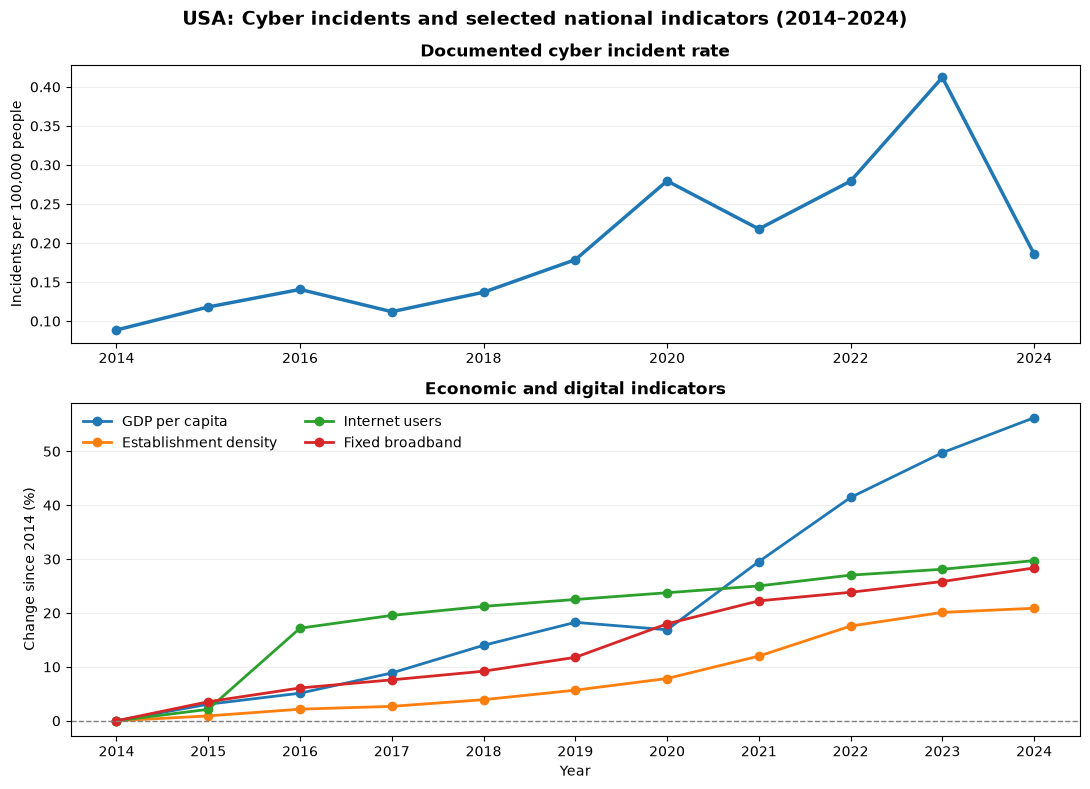

In [7]:

# Plot incident rates separately from economic and digital trends
trend_columns = [
    "gdp_per_capita",
    "establishment_density",
    "internet_users_pct",
    "fixed_broadband_per_100",
]

trend_labels = {
    "gdp_per_capita": "GDP per capita",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

trend = df_analysis.set_index("year")[trend_columns]
relative_change = (trend.div(trend.iloc[0]) - 1) * 100

fig, axes = plt.subplots(
    2, 1, figsize=(11, 8),
    sharex=False,
    gridspec_kw={"height_ratios": [1, 1.2]},
)

axes[0].plot(
    df_analysis["year"],
    df_analysis["incident_rate"],
    color="tab:blue",
    marker="o",
    linewidth=2.5,
)

axes[0].set_title("Documented cyber incident rate", fontweight="bold")
axes[0].set_ylabel("Incidents per 100,000 people")
axes[0].grid(axis="y", alpha=0.2)

for column in trend_columns:
    axes[1].plot(
        relative_change.index,
        relative_change[column],
        marker="o",
        linewidth=2,
        label=trend_labels[column],
    )

axes[1].axhline(0, color="gray", linewidth=1, linestyle="--")
axes[1].set_title("Economic and digital indicators", fontweight="bold")
axes[1].set_ylabel("Change since 2014 (%)")
axes[1].set_xlabel("Year")
axes[1].set_xticks(df_analysis["year"])
axes[1].grid(axis="y", alpha=0.2)
axes[1].legend(frameon=False, ncol=2)

fig.suptitle(
    "USA: Cyber incidents and selected national indicators (2014–2024)",
    fontsize=14,
    fontweight="bold",
)

fig.tight_layout()
plt.show()


## 3. Correlations and hypothesis tests

Calculate Pearson and Spearman correlations for all ten indicators (2014–2024). Report the associations relevant to H1–H3, sample size, and uncertainty without treating statistical significance as proof of causation.

### 3.1 Pearson correlation matrix


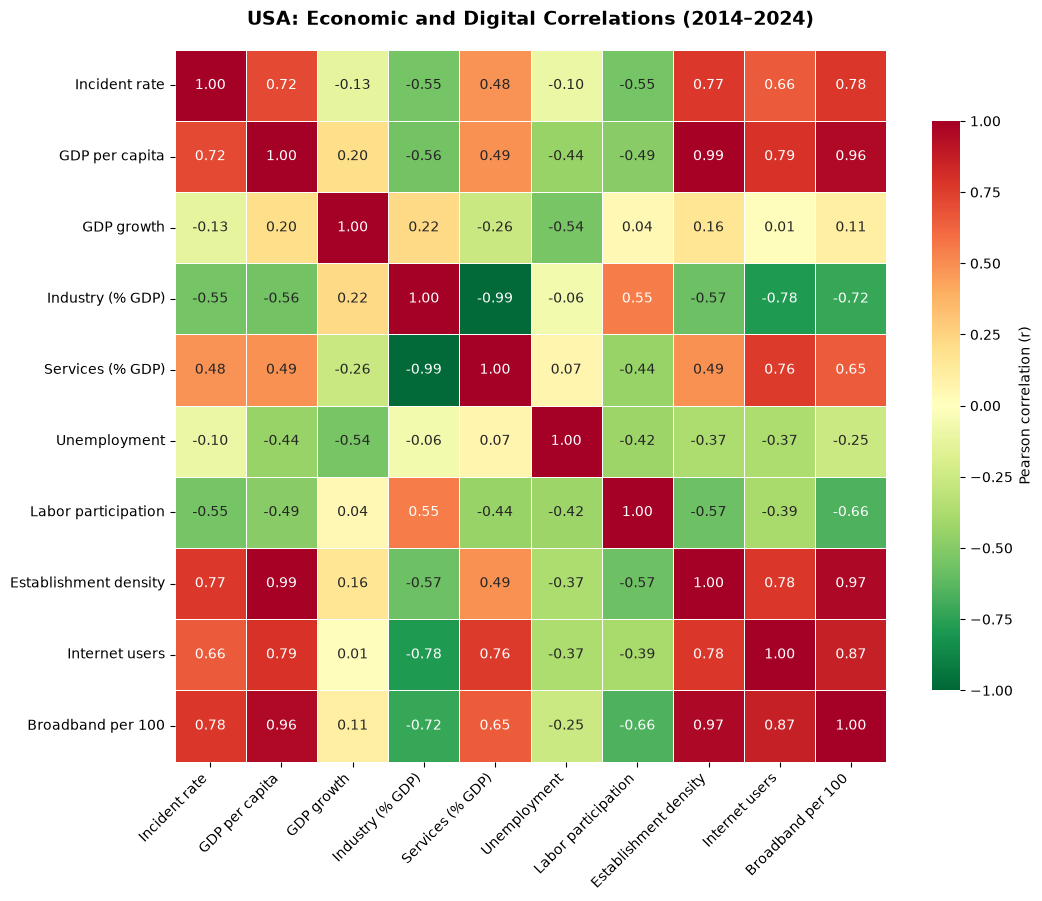

In [10]:

# Pearson correlation matrix for all ten indicators
pearson_corr = df_analysis[factors].corr(method="pearson")

labels = [
    "Incident rate",
    "GDP per capita",
    "GDP growth",
    "Industry (% GDP)",
    "Services (% GDP)",
    "Unemployment",
    "Labor participation",
    "Establishment density",
    "Internet users",
    "Broadband per 100",
]

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 10},
    cbar_kws={
        "label": "Pearson correlation (r)",
        "shrink": 0.8,
    },
    ax=ax,
)

ax.set_title(
    "USA: Economic and Digital Correlations (2014–2024)",
    fontsize=14,
    fontweight="bold",
    pad=18,
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=10,
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=10,
)

# Save the correlation matrix
figure_name = "01_pearson_correlation_matrix_2014_2024.png"

output_dirs = [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]

for output_dir in output_dirs:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

fig.tight_layout()
plt.show()


### 3.2 Key findings

- The strongest positive correlations with documented incident rates were observed for fixed broadband subscriptions ($r=0.78$), establishment density ($r=0.77$), GDP per capita ($r=0.72$), and internet usage ($r=0.66$).
- GDP growth ($r=-0.13$) and unemployment ($r=-0.10$) showed weak associations with incident rates.
- GDP per capita, establishment density, and fixed broadband were highly correlated with one another ($r=0.96$–$0.99$), suggesting potentially overlapping time trends.
- Industry and services shares showed an almost perfect negative correlation ($r=-0.99$), reflecting their structural relationship.

**Interpretation:** Economic development and digitalization are positively associated with documented incident rates in the observed period. However, these relationships may partly reflect shared time trends and do not establish causation.



### 3.3 Normality assessment

The Shapiro–Wilk test is applied to all ten indicators ($n=11$, $\alpha=0.05$) before selecting correlation methods.

- $H_0$: The data follow a normal distribution.
- $H_1$: The data do not follow a normal distribution.

A p-value below 0.05 indicates evidence against normality. A p-value of 0.05 or higher does not establish that the distribution is normal.


In [13]:
# Test normality of all ten indicators
normality_results = []

for factor in factors:
    statistic, p_value = shapiro(df_analysis[factor])

    normality_results.append({
        "Indicator": factor,
        "Shapiro W": statistic,
        "p-value": p_value,
        "Reject normality (p < 0.05)": p_value < 0.05,
    })

normality_df = pd.DataFrame(normality_results)

display(normality_df.round({
    "Shapiro W": 4,
    "p-value": 4,
}))

,Indicator,Shapiro W,p-value,Reject normality (p < 0.05)
0,incident_rate,0.8939,0.1557,False
1,gdp_per_capita,0.9033,0.2025,False
2,gdp_growth,0.7558,0.0025,True
3,industry_gdp_pct,0.9389,0.5073,False
4,services_gdp_pct,0.9325,0.4369,False
5,unemployment_rate,0.8381,0.0298,True
6,labor_force_participation,0.9515,0.6633,False
7,establishment_density,0.8702,0.0779,False
8,internet_users_pct,0.8229,0.0188,True
9,fixed_broadband_per_100,0.9339,0.4520,False


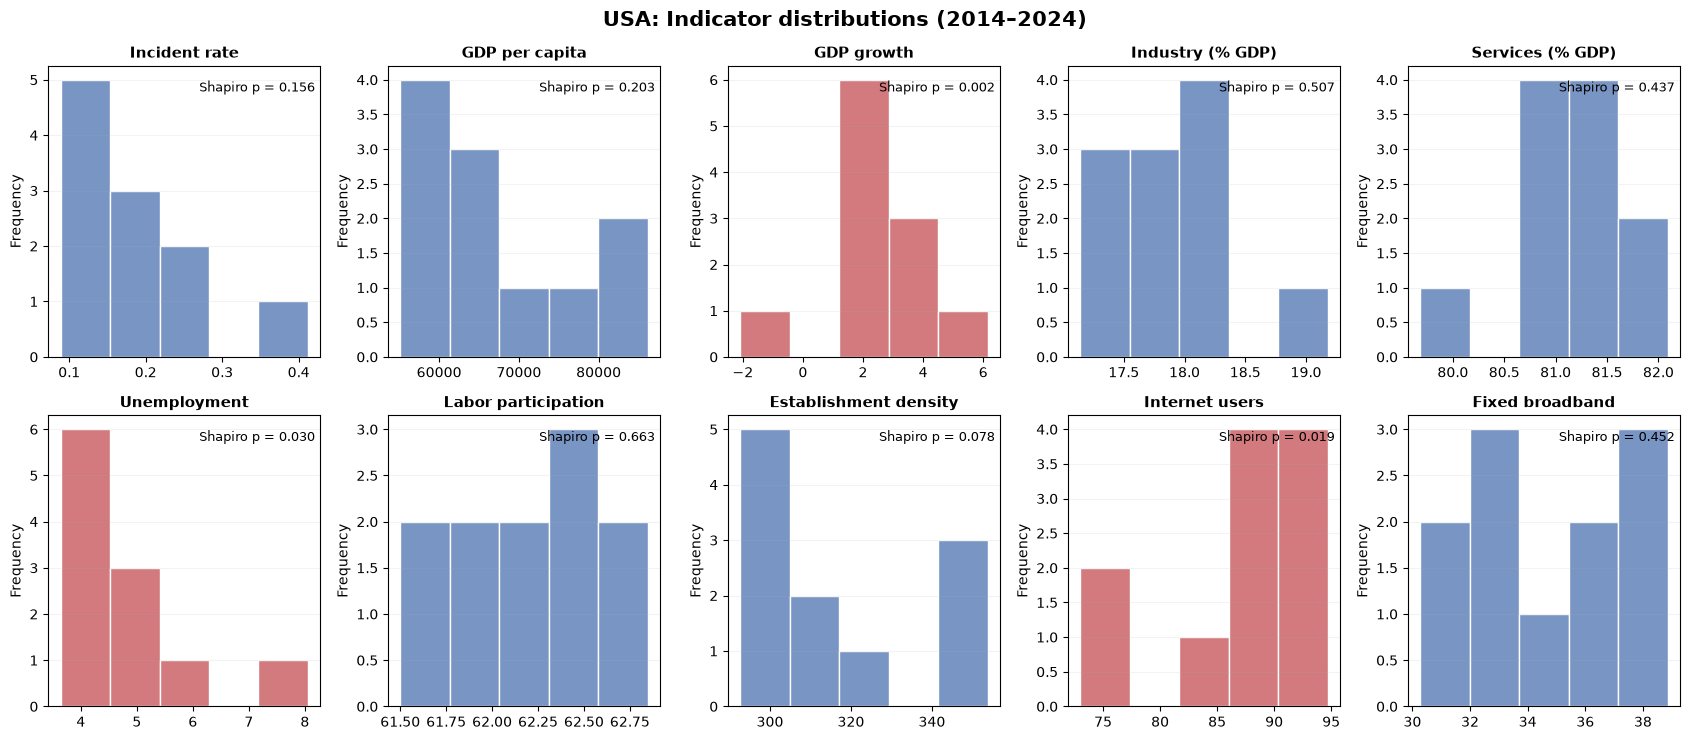

In [14]:
# Visualize the distributions of all ten indicators
indicator_labels = {
    "incident_rate": "Incident rate",
    "gdp_per_capita": "GDP per capita",
    "gdp_growth": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "labor_force_participation": "Labor participation",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

fig, axes = plt.subplots(2, 5, figsize=(17, 7.5))
axes = axes.flatten()

for ax, factor in zip(axes, factors):
    values = df_analysis[factor].dropna()

    p_value = normality_df.loc[
        normality_df["Indicator"] == factor, "p-value"
    ].iloc[0]

    color = "#C44E52" if p_value < 0.05 else "#4C72B0"

    sns.histplot(
        values,
        bins=5,
        color=color,
        edgecolor="white",
        ax=ax,
    )

    ax.set_title(
        indicator_labels[factor],
        fontsize=11,
        fontweight="bold",
    )
    ax.text(
        0.98, 0.95,
        f"Shapiro p = {p_value:.3f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )

    ax.set_xlabel("")
    ax.set_ylabel("Frequency")
    ax.grid(axis="y", alpha=0.15)

fig.suptitle(
    "USA: Indicator distributions (2014–2024)",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout()
plt.show()


### 3.5 Correlation tests

Based on the Shapiro–Wilk results, Pearson correlation is used when normality is not rejected for either variable, while Spearman correlation is used when normality is rejected.

For each of the nine factors, we test:

- $H_0$: There is no association with the documented incident rate.
- $H_1$: There is an association with the documented incident rate.

All tests are two-sided ($\alpha = 0.05$). Results are exploratory because annual observations may share time trends and are not necessarily independent.


In [17]:
# Select correlation methods based on Shapiro-Wilk results
normality_p = normality_df.set_index("Indicator")["p-value"]

results = []

for factor in factors:
    if factor == "incident_rate":
        continue

    use_spearman = (
        normality_p["incident_rate"] < 0.05
        or normality_p[factor] < 0.05
    )

    if use_spearman:
        coefficient, p_value = spearmanr(
            df_analysis[factor],
            df_analysis["incident_rate"],
        )
        method = "Spearman"
    else:
        coefficient, p_value = pearsonr(
            df_analysis[factor],
            df_analysis["incident_rate"],
        )
        method = "Pearson"

    results.append({
        "Factor": factor,
        "Method": method,
        "N": len(df_analysis),
        "Correlation": coefficient,
        "p-value": p_value,
    })

correlation_tests = pd.DataFrame(results)

correlation_tests["BH-adjusted p"] = multipletests(
    correlation_tests["p-value"],
    method="fdr_bh",
)[1]

correlation_tests["Significant (BH)"] = (
    correlation_tests["BH-adjusted p"] < 0.05
)

correlation_tests = correlation_tests.sort_values(
    "Correlation",
    key=lambda values: values.abs(),
    ascending=False,
).reset_index(drop=True)

display(
    correlation_tests.round({
        "Correlation": 3,
        "p-value": 4,
        "BH-adjusted p": 4,
    })
)


,Factor,Method,N,Correlation,p-value,BH-adjusted p,Significant (BH)
0,internet_users_pct,Spearman,11,0.836,0.0013,0.0120,True
1,fixed_broadband_per_100,Pearson,11,0.779,0.0047,0.0164,True
2,establishment_density,Pearson,11,0.771,0.0055,0.0164,True
3,gdp_per_capita,Pearson,11,0.717,0.0131,0.0294,True
4,industry_gdp_pct,Pearson,11,-0.552,0.0782,0.1176,False
5,labor_force_participation,Pearson,11,-0.552,0.0784,0.1176,False
6,services_gdp_pct,Pearson,11,0.484,0.1313,0.1688,False
7,unemployment_rate,Spearman,11,-0.318,0.3403,0.3828,False
8,gdp_growth,Spearman,11,0.064,0.8525,0.8525,False



### 3.6 Key findings

Nine economic and digital indicators were tested against the documented cyber incident rate in the USA (2014–2024, $n=11$).

Four indicators showed statistically significant positive associations after Benjamini–Hochberg correction ($\alpha=0.05$):

- **Internet users:** Spearman $\rho=0.836$, adjusted $p=0.0120$.
- **Fixed broadband:** Pearson $r=0.779$, adjusted $p=0.0164$.
- **Establishment density:** Pearson $r=0.771$, adjusted $p=0.0164$.
- **GDP per capita:** Pearson $r=0.717$, adjusted $p=0.0294$.

The remaining five indicators did not show statistically significant associations after correction.

**Interpretation:** Digitalization, establishment density, and GDP per capita are positively associated with documented incident rates. However, these findings are exploratory and may be affected by shared time trends, influential years, and the small sample size. Statistical significance does not establish causation.


### 3.7 Statistical significance of factors

The figure summarizes the associations between nine economic and digital indicators and documented cyber incident rates. Statistically significant associations after Benjamini–Hochberg correction ($p_{\mathrm{BH}} < 0.05$) are highlighted in green.


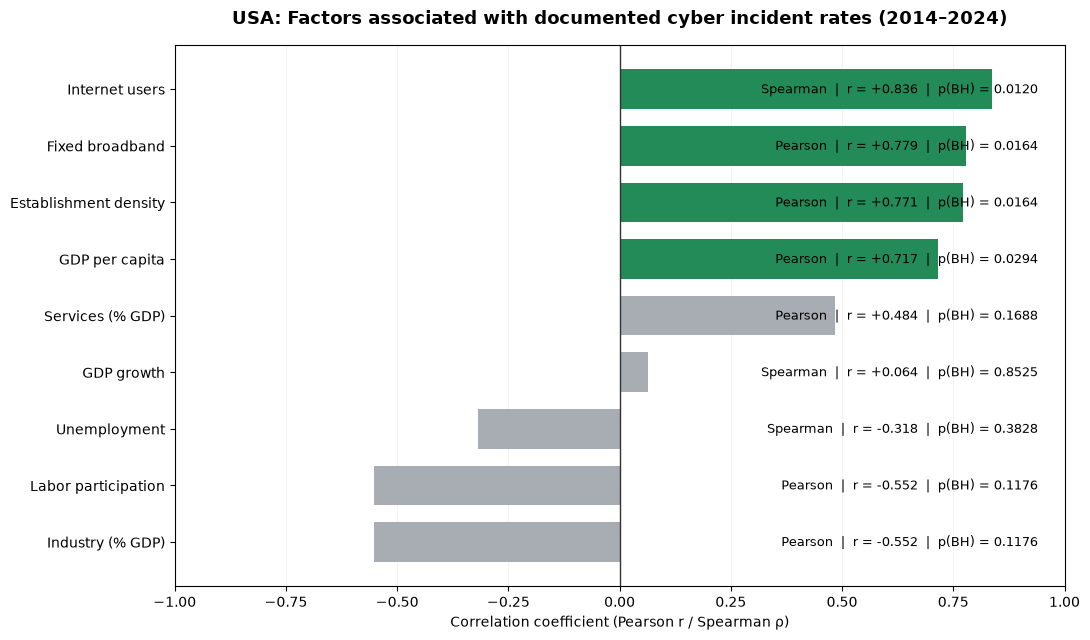

In [18]:
# Visualize correlation strength and BH-adjusted significance
plot_df = correlation_tests.copy().sort_values("Correlation")

factor_labels = {
    "gdp_per_capita": "GDP per capita",
    "gdp_growth": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate": "Unemployment",
    "labor_force_participation": "Labor participation",
    "establishment_density": "Establishment density",
    "internet_users_pct": "Internet users",
    "fixed_broadband_per_100": "Fixed broadband",
}

fig, ax = plt.subplots(figsize=(11, 6.5))

colors = [
    "#228B57" if significant else "#A8ADB4"
    for significant in plot_df["Significant (BH)"]
]

bars = ax.barh(
    plot_df["Factor"].map(factor_labels),
    plot_df["Correlation"],
    color=colors,
    height=0.7,
)

for bar, (_, row) in zip(bars, plot_df.iterrows()):
    coefficient = row["Correlation"]
    adjusted_p = row["BH-adjusted p"]

    ax.text(
        0.97,
        bar.get_y() + bar.get_height() / 2,
        f"{row['Method']}  |  r = {coefficient:+.3f}  |  p(BH) = {adjusted_p:.4f}",
        va="center",
        ha="right",
        fontsize=9,
        transform=ax.get_yaxis_transform(),
    )

ax.axvline(0, color="#333333", linewidth=1)
ax.set_xlim(-1, 1)
ax.set_xlabel("Correlation coefficient (Pearson r / Spearman ρ)")
ax.set_title(
    "USA: Factors associated with documented cyber incident rates (2014–2024)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

fig.tight_layout()

# Save figure
figure_name = "01_incident_rate_factor_significance_2014_2024.png"

for output_dir in [
    PROJECT_ROOT / "figures/factors/static",
    PROJECT_ROOT / "ugotovitve/dejavnike",
]:
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        output_dir / figure_name,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

plt.show()


## 4. Answers and interpretation

Answer Q1–Q3 individually in a few sentences using the observed coefficients and key limitations. Note that the eleven annual observations are not independent country-level replications and that common trends may explain some associations. More detailed sensitivity checks are reserved for `04_usa_robustness.ipynb`.

**Q1 — Internet adoption:** To be completed after analysis.  
**Q2 — Establishment density:** To be completed after analysis.  
**Q3 — GDP per capita:** To be completed after analysis.